Number of images: 96
Number of masks: 96
Abyssinian_1.jpg <-> Abyssinian_1.png
Abyssinian_10.jpg <-> Abyssinian_10.png
Abyssinian_11.jpg <-> Abyssinian_11.png
Abyssinian_12.jpg <-> Abyssinian_12.png
Abyssinian_13.jpg <-> Abyssinian_13.png
Image shape: (368, 500, 3)
Mask shape: (368, 500)
Mask unique values: [0 1]


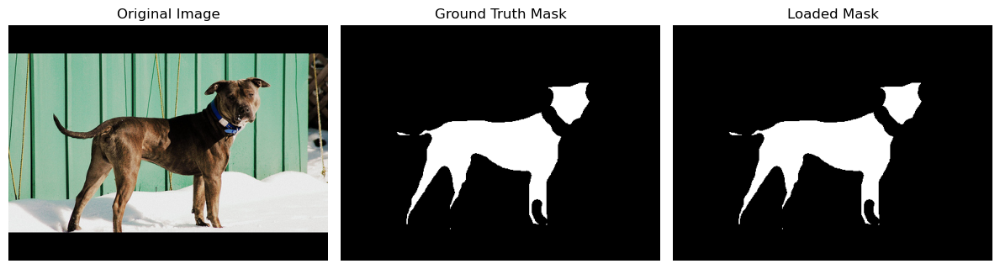

In [16]:
import os
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.cluster import KMeans

# Dataset paths
DATASET_DIR = Path("Oxford-IIIT Pet Subset")
IMAGE_DIR = DATASET_DIR / "image"
MASK_DIR = DATASET_DIR / "annotation"

# Load real image files
image_paths = sorted(list(IMAGE_DIR.glob("*.jpg")))
mask_paths = sorted(list(MASK_DIR.glob("*.png")))

print(f"Number of images: {len(image_paths)}")
print(f"Number of masks: {len(mask_paths)}")

for i in range(min(5, len(image_paths))):
    print(image_paths[i].name, "<->", mask_paths[i].name)


def load_image(image_path):
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"Could not load image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image


def load_mask(mask_path):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not load mask: {mask_path}")

    # 1 = foreground, 2 = background, 3 = not classified
    # Convert to binary mask: foreground = 1, everything else = 0
    binary_mask = np.where(mask == 1, 1, 0).astype(np.uint8)
    return binary_mask


def compute_iou(y_true, y_pred):
    y_true = y_true.astype(bool)
    y_pred = y_pred.astype(bool)

    intersection = np.logical_and(y_true, y_pred).sum()
    union = np.logical_or(y_true, y_pred).sum()

    if union == 0:
        return 1.0 if intersection == 0 else 0.0

    return intersection / union


def compute_dice(y_true, y_pred):
    y_true = y_true.astype(bool)
    y_pred = y_pred.astype(bool)

    intersection = np.logical_and(y_true, y_pred).sum()
    total = y_true.sum() + y_pred.sum()

    if total == 0:
        return 1.0

    return (2 * intersection) / total

def compute_confusion_counts(gt_mask, pred_mask):
    gt = (gt_mask > 0).astype(np.uint8)
    pred = (pred_mask > 0).astype(np.uint8)

    tp = np.logical_and(gt == 1, pred == 1).sum()
    fp = np.logical_and(gt == 0, pred == 1).sum()
    fn = np.logical_and(gt == 1, pred == 0).sum()

    return tp, fp, fn


def compute_global_iou(tp, fp, fn):
    denom = tp + fp + fn
    if denom == 0:
        return 1.0
    return tp / denom


def compute_global_dice(tp, fp, fn):
    denom = 2 * tp + fp + fn
    if denom == 0:
        return 1.0
    return (2 * tp) / denom


def show_results(image, gt_mask, pred_mask, title="Segmentation Result"):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(gt_mask, cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask, cmap="gray")
    plt.title(title)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# Quick test
sample_idx = 21

image = load_image(image_paths[sample_idx])
mask = load_mask(mask_paths[sample_idx])

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask unique values:", np.unique(mask))

show_results(image, mask, mask, title="Loaded Mask")

In [ ]:
# Task 1: Edge-Based Segmentation

In [17]:
def edge_based_segmentation(image, low_threshold=50, high_threshold=120, min_area=500):
    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Step 1: Smooth image
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Step 2: Edge detection
    edges = cv2.Canny(blurred, low_threshold, high_threshold)

    # Step 3: Morphological connection of broken edges
    kernel = np.ones((5, 5), np.uint8)
    dilated = cv2.dilate(edges, kernel, iterations=1)
    closed = cv2.morphologyEx(dilated, cv2.MORPH_CLOSE, kernel, iterations=2)

    # Step 4: Find contours from cleaned edge map
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    pred_mask = np.zeros(gray.shape, dtype=np.uint8)

    # Fill contours above minimum area
    for contour in contours:
        area = cv2.contourArea(contour)
        if area > min_area:
            cv2.drawContours(pred_mask, [contour], -1, 1, thickness=cv2.FILLED)

    # Step 5: Extra cleanup inspired by Week 8 region-based processing
    pred_mask = cv2.morphologyEx(pred_mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    pred_mask = cv2.morphologyEx(pred_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    # Step 6: Keep only the largest connected component
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(pred_mask.astype(np.uint8), connectivity=8)

    cleaned_mask = np.zeros_like(pred_mask)

    if num_labels > 1:
        # Ignore background at index 0
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        largest_area = stats[largest_label, cv2.CC_STAT_AREA]

        if largest_area > min_area:
            cleaned_mask[labels == largest_label] = 1

    # Step 7: Optional hole filling using contour redraw
    final_mask = np.zeros_like(cleaned_mask)
    final_contours, _ = cv2.findContours((cleaned_mask * 255).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(final_mask, final_contours, -1, 1, thickness=cv2.FILLED)

    return final_mask.astype(np.uint8), edges, dilated, closed

 10%|█         | 10/96 [00:00<00:01, 45.02it/s]

Abyssinian_1.jpg: IoU=0.242, Dice=0.390, Saved: dataset/predictions_edge\Abyssinian_1_edge.png
Abyssinian_10.jpg: IoU=0.436, Dice=0.607, Saved: dataset/predictions_edge\Abyssinian_10_edge.png
Abyssinian_11.jpg: IoU=0.663, Dice=0.797, Saved: dataset/predictions_edge\Abyssinian_11_edge.png
Abyssinian_12.jpg: IoU=0.161, Dice=0.277, Saved: dataset/predictions_edge\Abyssinian_12_edge.png
Abyssinian_13.jpg: IoU=0.491, Dice=0.659, Saved: dataset/predictions_edge\Abyssinian_13_edge.png
Abyssinian_14.jpg: IoU=0.062, Dice=0.116, Saved: dataset/predictions_edge\Abyssinian_14_edge.png
Abyssinian_15.jpg: IoU=0.560, Dice=0.718, Saved: dataset/predictions_edge\Abyssinian_15_edge.png
Abyssinian_16.jpg: IoU=0.170, Dice=0.291, Saved: dataset/predictions_edge\Abyssinian_16_edge.png
Abyssinian_17.jpg: IoU=0.142, Dice=0.248, Saved: dataset/predictions_edge\Abyssinian_17_edge.png
Abyssinian_18.jpg: IoU=0.118, Dice=0.211, Saved: dataset/predictions_edge\Abyssinian_18_edge.png
Abyssinian_19.jpg: IoU=0.701, Di

 22%|██▏       | 21/96 [00:00<00:01, 47.41it/s]

Abyssinian_2.jpg: IoU=0.144, Dice=0.252, Saved: dataset/predictions_edge\Abyssinian_2_edge.png
Abyssinian_20.jpg: IoU=0.341, Dice=0.509, Saved: dataset/predictions_edge\Abyssinian_20_edge.png
Abyssinian_3.jpg: IoU=0.176, Dice=0.299, Saved: dataset/predictions_edge\Abyssinian_3_edge.png
Abyssinian_4.jpg: IoU=0.151, Dice=0.262, Saved: dataset/predictions_edge\Abyssinian_4_edge.png
Abyssinian_5.jpg: IoU=0.594, Dice=0.746, Saved: dataset/predictions_edge\Abyssinian_5_edge.png
Abyssinian_6.jpg: IoU=0.060, Dice=0.112, Saved: dataset/predictions_edge\Abyssinian_6_edge.png
Abyssinian_7.jpg: IoU=0.358, Dice=0.528, Saved: dataset/predictions_edge\Abyssinian_7_edge.png
Abyssinian_8.jpg: IoU=0.201, Dice=0.334, Saved: dataset/predictions_edge\Abyssinian_8_edge.png
Abyssinian_9.jpg: IoU=0.736, Dice=0.848, Saved: dataset/predictions_edge\Abyssinian_9_edge.png
american_pit_bull_terrier_1.jpg: IoU=0.352, Dice=0.521, Saved: dataset/predictions_edge\american_pit_bull_terrier_1_edge.png


 27%|██▋       | 26/96 [00:00<00:01, 43.12it/s]

american_pit_bull_terrier_10.jpg: IoU=0.163, Dice=0.280, Saved: dataset/predictions_edge\american_pit_bull_terrier_10_edge.png
american_pit_bull_terrier_11.jpg: IoU=0.216, Dice=0.355, Saved: dataset/predictions_edge\american_pit_bull_terrier_11_edge.png
american_pit_bull_terrier_12.jpg: IoU=0.109, Dice=0.196, Saved: dataset/predictions_edge\american_pit_bull_terrier_12_edge.png
american_pit_bull_terrier_13.jpg: IoU=0.192, Dice=0.322, Saved: dataset/predictions_edge\american_pit_bull_terrier_13_edge.png
american_pit_bull_terrier_14.jpg: IoU=0.174, Dice=0.297, Saved: dataset/predictions_edge\american_pit_bull_terrier_14_edge.png
american_pit_bull_terrier_15.jpg: IoU=0.078, Dice=0.144, Saved: dataset/predictions_edge\american_pit_bull_terrier_15_edge.png
american_pit_bull_terrier_16.jpg: IoU=0.570, Dice=0.726, Saved: dataset/predictions_edge\american_pit_bull_terrier_16_edge.png
american_pit_bull_terrier_17.jpg: IoU=0.552, Dice=0.711, Saved: dataset/predictions_edge\american_pit_bull_terr

... (10 outputs left out)

 88%|████████▊ | 84/96 [00:01<00:00, 40.23it/s]

Egyptian_Mau_13.jpg: IoU=0.508, Dice=0.674, Saved: dataset/predictions_edge\Egyptian_Mau_13_edge.png
Egyptian_Mau_14.jpg: IoU=0.483, Dice=0.652, Saved: dataset/predictions_edge\Egyptian_Mau_14_edge.png
Egyptian_Mau_15.jpg: IoU=0.277, Dice=0.434, Saved: dataset/predictions_edge\Egyptian_Mau_15_edge.png
Egyptian_Mau_16.jpg: IoU=0.622, Dice=0.767, Saved: dataset/predictions_edge\Egyptian_Mau_16_edge.png
Egyptian_Mau_18.jpg: IoU=0.201, Dice=0.335, Saved: dataset/predictions_edge\Egyptian_Mau_18_edge.png
Egyptian_Mau_19.jpg: IoU=0.366, Dice=0.536, Saved: dataset/predictions_edge\Egyptian_Mau_19_edge.png
Egyptian_Mau_2.jpg: IoU=0.645, Dice=0.784, Saved: dataset/predictions_edge\Egyptian_Mau_2_edge.png


100%|██████████| 96/96 [00:02<00:00, 40.24it/s]

Egyptian_Mau_20.jpg: IoU=0.000, Dice=0.000, Saved: dataset/predictions_edge\Egyptian_Mau_20_edge.png
Egyptian_Mau_3.jpg: IoU=0.572, Dice=0.728, Saved: dataset/predictions_edge\Egyptian_Mau_3_edge.png
Egyptian_Mau_4.jpg: IoU=0.529, Dice=0.692, Saved: dataset/predictions_edge\Egyptian_Mau_4_edge.png
Egyptian_Mau_5.jpg: IoU=0.554, Dice=0.713, Saved: dataset/predictions_edge\Egyptian_Mau_5_edge.png
Egyptian_Mau_6.jpg: IoU=0.646, Dice=0.785, Saved: dataset/predictions_edge\Egyptian_Mau_6_edge.png
Egyptian_Mau_7.jpg: IoU=0.688, Dice=0.815, Saved: dataset/predictions_edge\Egyptian_Mau_7_edge.png
Egyptian_Mau_8.jpg: IoU=0.667, Dice=0.800, Saved: dataset/predictions_edge\Egyptian_Mau_8_edge.png
Egyptian_Mau_9.jpg: IoU=0.710, Dice=0.830, Saved: dataset/predictions_edge\Egyptian_Mau_9_edge.png

--- Task 1: Edge-Based Segmentation Batch Evaluation ---
Total images processed: 96
Average IoU (Edge-Based): 0.3457
Average Dice (Edge-Based): 0.4676
Global IoU (Edge-Based): 0.2916
Global Dice (Edge-Base

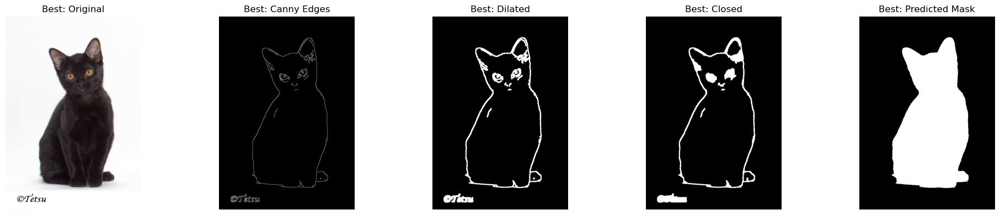

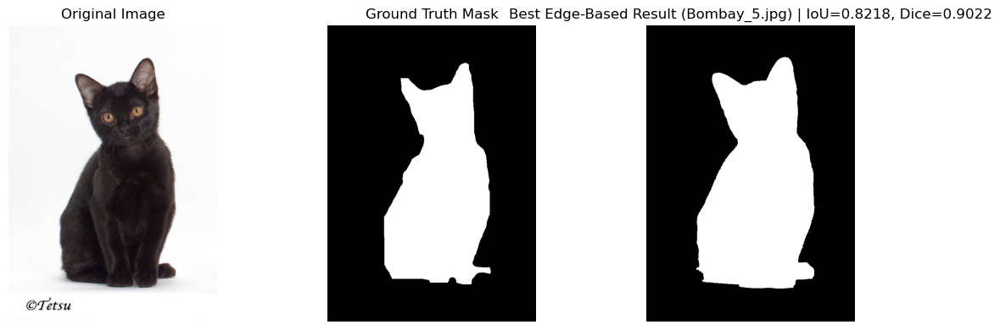

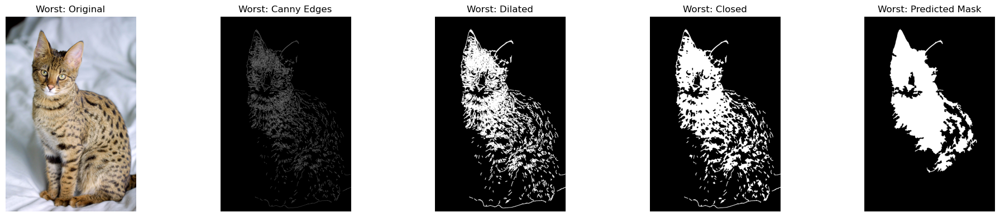

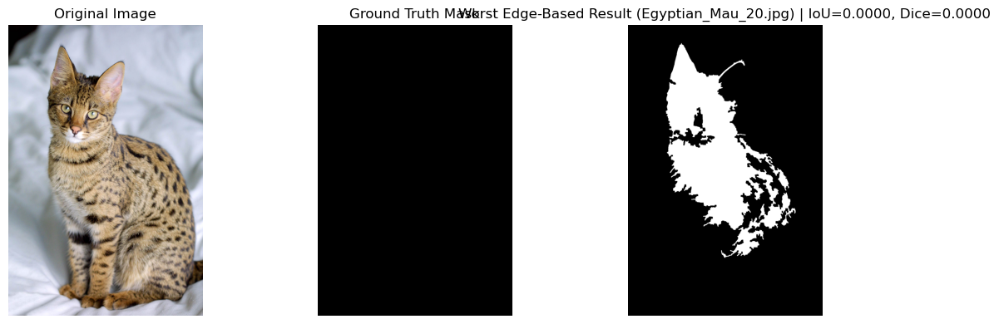

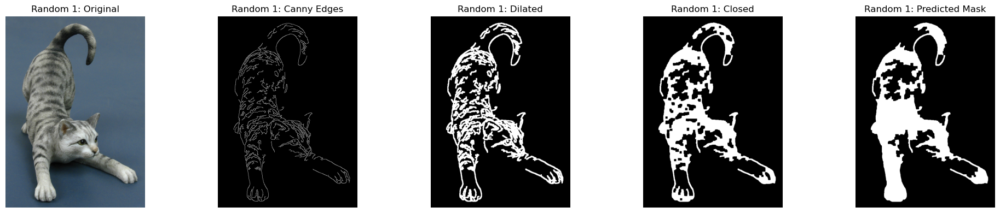

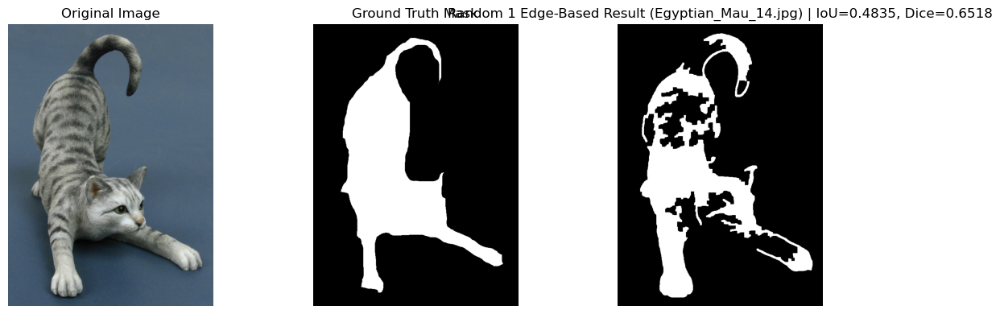

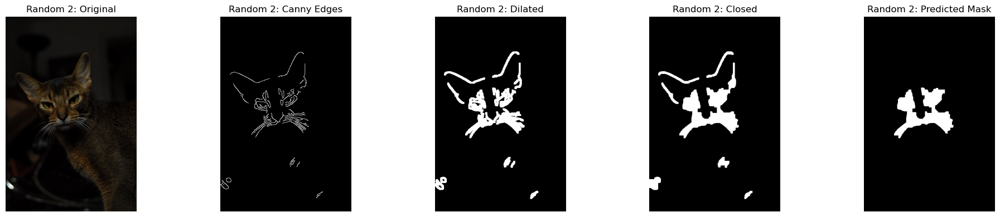

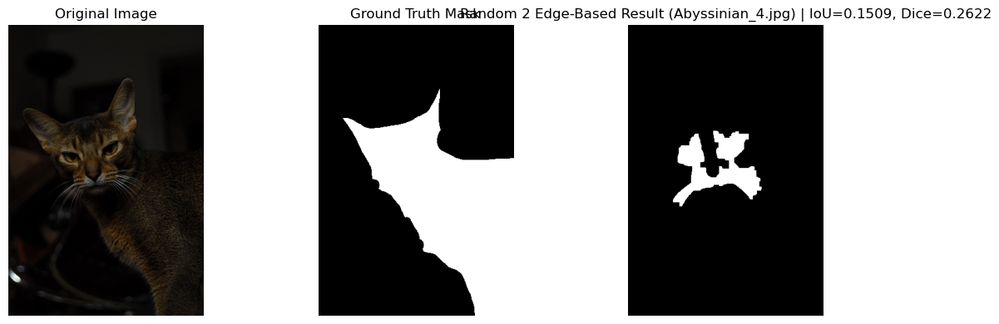

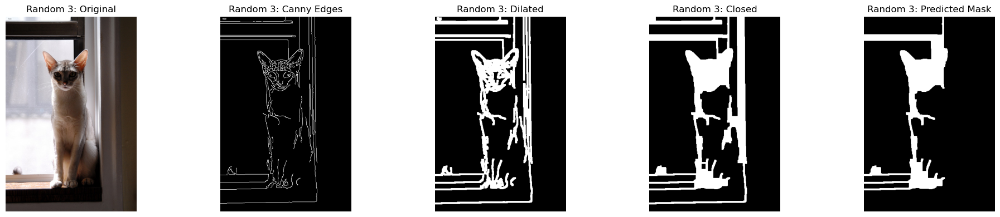

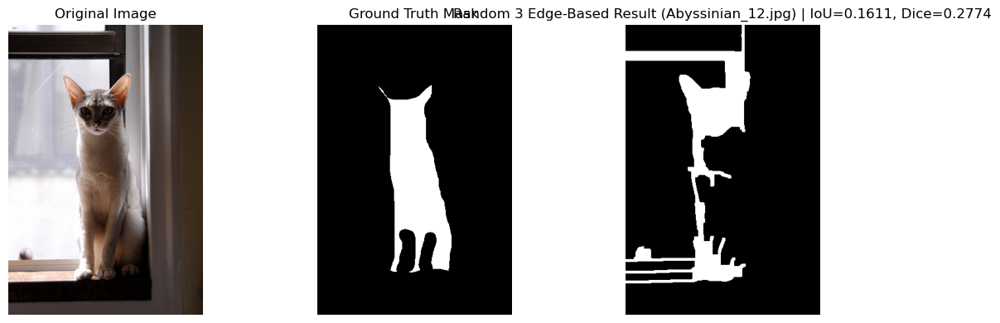

In [18]:
# Task 1: Edge-Based Segmentation - Batch Evaluation + 5 Visual Examples

save_dir = "results/predictions_edge"
os.makedirs(save_dir, exist_ok=True)

print_each_image = True
random.seed(42)

edge_results = []

# For global metrics
edge_tp = 0
edge_fp = 0
edge_fn = 0


# 1. Batch process full dataset
for idx, (img_path, mask_path) in enumerate(tqdm(zip(image_paths, mask_paths), total=len(image_paths))):
    image = load_image(img_path)
    gt_mask = load_mask(mask_path)

    pred_mask, edges, dilated, closed = edge_based_segmentation(image)

    # Ensure binary masks
    gt_mask = (gt_mask > 0).astype(np.uint8)
    pred_mask = (pred_mask > 0).astype(np.uint8)

    iou = compute_iou(gt_mask, pred_mask)
    dice = compute_dice(gt_mask, pred_mask)

    # Global counts
    tp, fp, fn = compute_confusion_counts(gt_mask, pred_mask)
    edge_tp += tp
    edge_fp += fp
    edge_fn += fn

    # Save prediction
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    save_path = os.path.join(save_dir, f"{base_name}_edge.png")
    cv2.imwrite(save_path, (pred_mask * 255).astype(np.uint8))

    if print_each_image:
        print(f"{os.path.basename(img_path)}: IoU={iou:.3f}, Dice={dice:.3f}, Saved: {save_path}")

    edge_results.append({
        "idx": idx,
        "img_path": img_path,
        "mask_path": mask_path,
        "image_name": os.path.basename(img_path),
        "image": image,
        "gt_mask": gt_mask,
        "pred_mask": pred_mask,
        "edges": edges,
        "dilated": dilated,
        "closed": closed,
        "iou": iou,
        "dice": dice,
        "save_path": save_path
    })


# 2. Summary metrics
edge_ious = [r["iou"] for r in edge_results]
edge_dices = [r["dice"] for r in edge_results]

edge_global_iou = compute_global_iou(edge_tp, edge_fp, edge_fn)
edge_global_dice = compute_global_dice(edge_tp, edge_fp, edge_fn)

print("\n--- Task 1: Edge-Based Segmentation Batch Evaluation ---")
print(f"Total images processed: {len(edge_results)}")
print(f"Average IoU (Edge-Based): {np.mean(edge_ious):.4f}")
print(f"Average Dice (Edge-Based): {np.mean(edge_dices):.4f}")
print(f"Global IoU (Edge-Based): {edge_global_iou:.4f}")
print(f"Global Dice (Edge-Based): {edge_global_dice:.4f}")


# 3. Best and worst case
best_case = max(edge_results, key=lambda x: x["iou"])
worst_case = min(edge_results, key=lambda x: x["iou"])

print("\nBest Case:")
print(f"Index: {best_case['idx']}, Image: {best_case['image_name']}, IoU: {best_case['iou']:.4f}, Dice: {best_case['dice']:.4f}")

print("\nWorst Case:")
print(f"Index: {worst_case['idx']}, Image: {worst_case['image_name']}, IoU: {worst_case['iou']:.4f}, Dice: {worst_case['dice']:.4f}")


# 4. Select 3 random examples
remaining_cases = [r for r in edge_results if r["idx"] not in [best_case["idx"], worst_case["idx"]]]
random_cases = random.sample(remaining_cases, 3)

print("\nRandom Examples:")
for i, case in enumerate(random_cases, 1):
    print(f"Random {i}: Index {case['idx']}, Image: {case['image_name']}, IoU: {case['iou']:.4f}, Dice: {case['dice']:.4f}")


# 5. Helper function to display
def show_edge_case_details(case, label="Example"):
    plt.figure(figsize=(20, 4))

    plt.subplot(1, 5, 1)
    plt.imshow(case["image"])
    plt.title(f"{label}: Original")
    plt.axis("off")

    plt.subplot(1, 5, 2)
    plt.imshow(case["edges"], cmap="gray")
    plt.title(f"{label}: Canny Edges")
    plt.axis("off")

    plt.subplot(1, 5, 3)
    plt.imshow(case["dilated"], cmap="gray")
    plt.title(f"{label}: Dilated")
    plt.axis("off")

    plt.subplot(1, 5, 4)
    plt.imshow(case["closed"], cmap="gray")
    plt.title(f"{label}: Closed")
    plt.axis("off")

    plt.subplot(1, 5, 5)
    plt.imshow(case["pred_mask"], cmap="gray")
    plt.title(f"{label}: Predicted Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    show_results(
        case["image"],
        case["gt_mask"],
        case["pred_mask"],
        title=f"{label} Edge-Based Result ({case['image_name']}) | IoU={case['iou']:.4f}, Dice={case['dice']:.4f}"
    )


# 6. Show 5 qualitative examples
show_edge_case_details(best_case, label="Best")
show_edge_case_details(worst_case, label="Worst")

for i, case in enumerate(random_cases, 1):
    show_edge_case_details(case, label=f"Random {i}")

In [ ]:
# Task 2:Region-Based Segmentation

In [19]:
# Task 2: Region-Based Segmentation using Region Growing

def region_based_segmentation(image, threshold=20, min_area=500):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    h, w = blurred.shape
    seed = (h // 2, w // 2)
    seed_value = int(blurred[seed])

    segmented = np.zeros((h, w), dtype=np.uint8)
    visited = np.zeros((h, w), dtype=bool)
    stack = [seed]

    while stack:
        x, y = stack.pop()

        if visited[x, y]:
            continue

        visited[x, y] = True

        if abs(int(blurred[x, y]) - seed_value) < threshold:
            segmented[x, y] = 1

            neighbors = [
                (x - 1, y),
                (x + 1, y),
                (x, y - 1),
                (x, y + 1)
            ]

            for nx, ny in neighbors:
                if 0 <= nx < h and 0 <= ny < w and not visited[nx, ny]:
                    stack.append((nx, ny))

    kernel = np.ones((5, 5), np.uint8)
    opened = cv2.morphologyEx(segmented, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(closed.astype(np.uint8), connectivity=8)

    pred_mask = np.zeros_like(closed, dtype=np.uint8)

    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        largest_area = stats[largest_label, cv2.CC_STAT_AREA]

        if largest_area > min_area:
            pred_mask[labels == largest_label] = 1

    return pred_mask.astype(np.uint8), gray, blurred, segmented, closed

  0%|          | 0/96 [00:00<?, ?it/s]

Abyssinian_1.jpg: IoU=0.331, Dice=0.498, Saved: dataset/predictions_region\Abyssinian_1_region.png


  6%|▋         | 6/96 [00:00<00:05, 17.43it/s]

Abyssinian_10.jpg: IoU=0.081, Dice=0.150, Saved: dataset/predictions_region\Abyssinian_10_region.png
Abyssinian_11.jpg: IoU=0.074, Dice=0.138, Saved: dataset/predictions_region\Abyssinian_11_region.png
Abyssinian_12.jpg: IoU=0.173, Dice=0.295, Saved: dataset/predictions_region\Abyssinian_12_region.png
Abyssinian_13.jpg: IoU=0.456, Dice=0.626, Saved: dataset/predictions_region\Abyssinian_13_region.png
Abyssinian_14.jpg: IoU=0.006, Dice=0.012, Saved: dataset/predictions_region\Abyssinian_14_region.png


  9%|▉         | 9/96 [00:00<00:06, 12.99it/s]

Abyssinian_15.jpg: IoU=0.082, Dice=0.151, Saved: dataset/predictions_region\Abyssinian_15_region.png
Abyssinian_16.jpg: IoU=0.128, Dice=0.226, Saved: dataset/predictions_region\Abyssinian_16_region.png
Abyssinian_17.jpg: IoU=0.393, Dice=0.564, Saved: dataset/predictions_region\Abyssinian_17_region.png
Abyssinian_18.jpg: IoU=0.012, Dice=0.023, Saved: dataset/predictions_region\Abyssinian_18_region.png
Abyssinian_19.jpg: IoU=0.305, Dice=0.468, Saved: dataset/predictions_region\Abyssinian_19_region.png


... (48 outputs left out)

 98%|█████████▊| 94/96 [00:11<00:00,  6.63it/s]

Egyptian_Mau_6.jpg: IoU=0.085, Dice=0.157, Saved: dataset/predictions_region\Egyptian_Mau_6_region.png
Egyptian_Mau_7.jpg: IoU=0.006, Dice=0.011, Saved: dataset/predictions_region\Egyptian_Mau_7_region.png


100%|██████████| 96/96 [00:11<00:00,  8.28it/s]


Egyptian_Mau_8.jpg: IoU=0.000, Dice=0.000, Saved: dataset/predictions_region\Egyptian_Mau_8_region.png
Egyptian_Mau_9.jpg: IoU=0.084, Dice=0.155, Saved: dataset/predictions_region\Egyptian_Mau_9_region.png

--- Task 2: Region-Based Segmentation Batch Evaluation ---
Total images processed: 96
Average IoU (Region-Based): 0.1553
Average Dice (Region-Based): 0.2138
Global IoU (Region-Based): 0.1357
Global Dice (Region-Based): 0.2389

Best Case:
Index: 76, Image: Bombay_9.jpg, IoU: 0.8654, Dice: 0.9279

Worst Case:
Index: 11, Image: Abyssinian_2.jpg, IoU: 0.0000, Dice: 0.0000

Random Examples:
Random 1: Index 83, Image: Egyptian_Mau_15.jpg, IoU: 0.0000, Dice: 0.0000
Random 2: Index 15, Image: Abyssinian_5.jpg, IoU: 0.0000, Dice: 0.0000
Random 3: Index 3, Image: Abyssinian_12.jpg, IoU: 0.1729, Dice: 0.2948


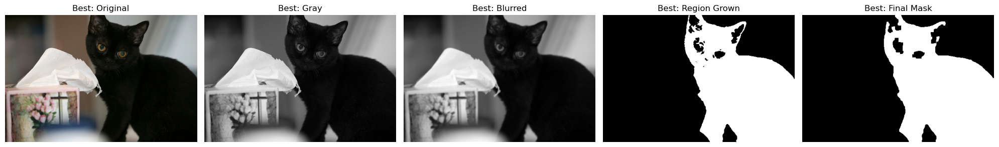

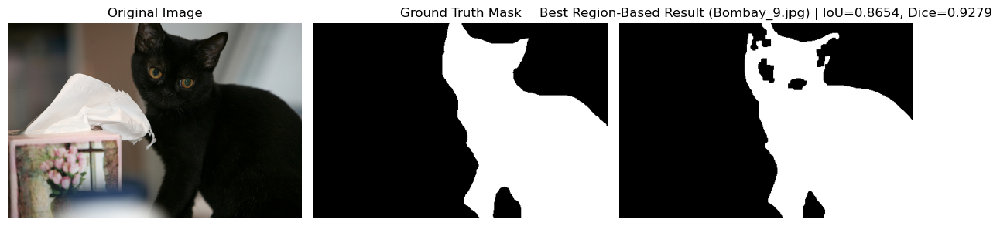

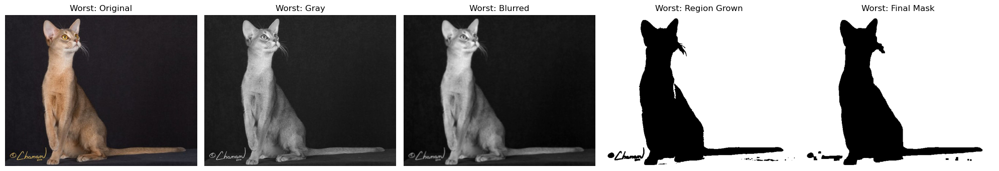

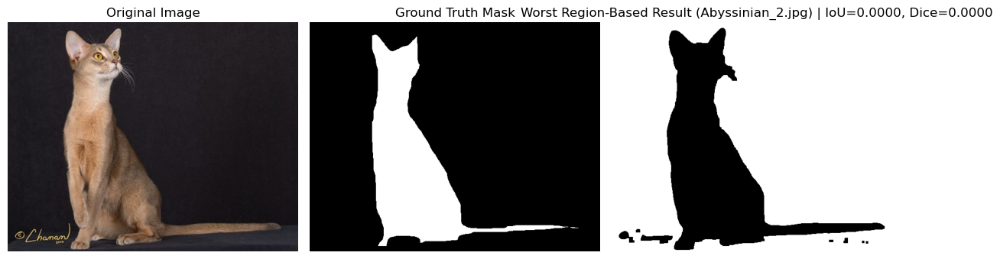

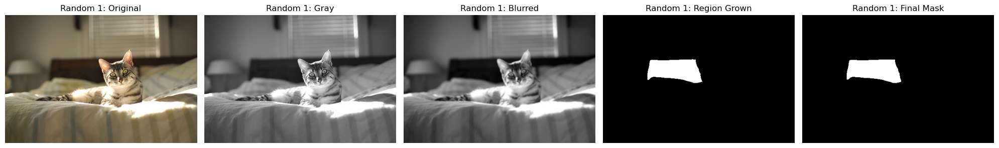

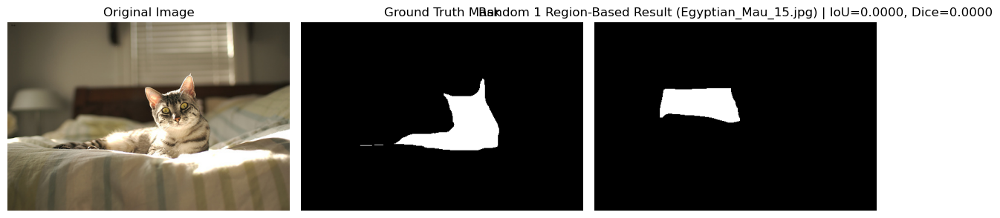

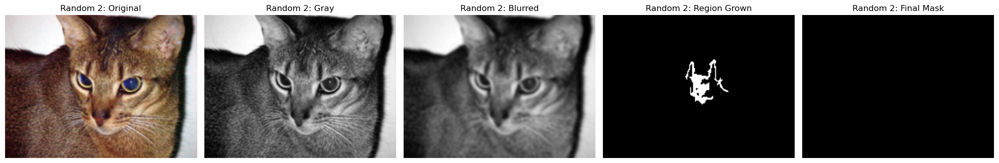

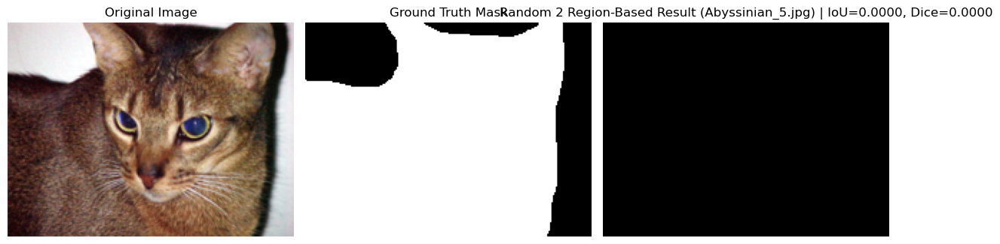

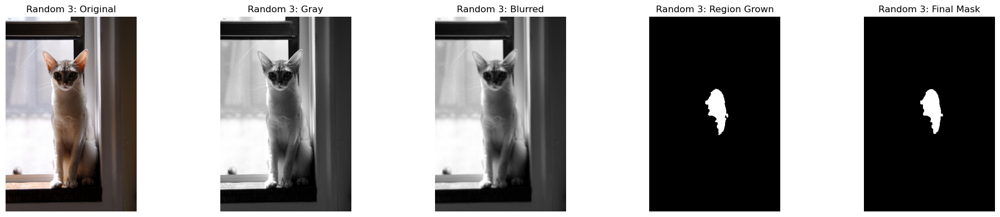

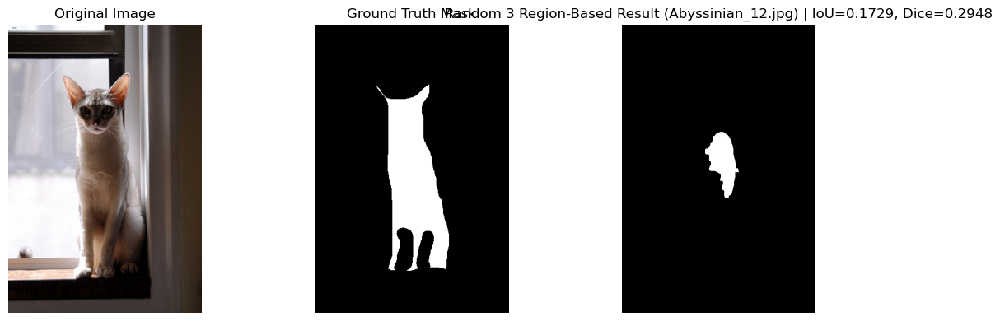

In [20]:
# Task 2: Region-Based Segmentation - Batch Evaluation + 5 Visual Examples

import os
import random
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

# Settings
save_dir = "results/predictions_region"
os.makedirs(save_dir, exist_ok=True)

print_each_image = True
random.seed(42)

region_results = []

# For global metrics
region_tp = 0
region_fp = 0
region_fn = 0


# 1. Batch process full dataset
for idx, (img_path, mask_path) in enumerate(tqdm(zip(image_paths, mask_paths), total=len(image_paths))):
    image = load_image(img_path)
    gt_mask = load_mask(mask_path)

    pred_mask, gray, blurred, segmented, closed = region_based_segmentation(image)

    # Ensure binary masks
    gt_mask = (gt_mask > 0).astype(np.uint8)
    pred_mask = (pred_mask > 0).astype(np.uint8)

    iou = compute_iou(gt_mask, pred_mask)
    dice = compute_dice(gt_mask, pred_mask)

    # Global counts
    tp, fp, fn = compute_confusion_counts(gt_mask, pred_mask)
    region_tp += tp
    region_fp += fp
    region_fn += fn

    # Save prediction
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    save_path = os.path.join(save_dir, f"{base_name}_region.png")
    cv2.imwrite(save_path, (pred_mask * 255).astype(np.uint8))

    if print_each_image:
        print(f"{os.path.basename(img_path)}: IoU={iou:.3f}, Dice={dice:.3f}, Saved: {save_path}")

    region_results.append({
        "idx": idx,
        "img_path": img_path,
        "mask_path": mask_path,
        "image_name": os.path.basename(img_path),
        "image": image,
        "gt_mask": gt_mask,
        "pred_mask": pred_mask,
        "gray": gray,
        "blurred": blurred,
        "segmented": segmented,
        "closed": closed,
        "iou": iou,
        "dice": dice,
        "save_path": save_path
    })


# 2. Summary metrics
region_ious = [r["iou"] for r in region_results]
region_dices = [r["dice"] for r in region_results]

region_global_iou = compute_global_iou(region_tp, region_fp, region_fn)
region_global_dice = compute_global_dice(region_tp, region_fp, region_fn)

print("\n--- Task 2: Region-Based Segmentation Batch Evaluation ---")
print(f"Total images processed: {len(region_results)}")
print(f"Average IoU (Region-Based): {np.mean(region_ious):.4f}")
print(f"Average Dice (Region-Based): {np.mean(region_dices):.4f}")
print(f"Global IoU (Region-Based): {region_global_iou:.4f}")
print(f"Global Dice (Region-Based): {region_global_dice:.4f}")


# 3. Best and worst case
best_case = max(region_results, key=lambda x: x["iou"])
worst_case = min(region_results, key=lambda x: x["iou"])

print("\nBest Case:")
print(f"Index: {best_case['idx']}, Image: {best_case['image_name']}, IoU: {best_case['iou']:.4f}, Dice: {best_case['dice']:.4f}")

print("\nWorst Case:")
print(f"Index: {worst_case['idx']}, Image: {worst_case['image_name']}, IoU: {worst_case['iou']:.4f}, Dice: {worst_case['dice']:.4f}")


# 4. Select 3 random examples
remaining_cases = [r for r in region_results if r["idx"] not in [best_case["idx"], worst_case["idx"]]]
random_cases = random.sample(remaining_cases, 3)

print("\nRandom Examples:")
for i, case in enumerate(random_cases, 1):
    print(f"Random {i}: Index {case['idx']}, Image: {case['image_name']}, IoU: {case['iou']:.4f}, Dice: {case['dice']:.4f}")


# 5. Helper function to display
def show_region_case_details(case, label="Example"):
    plt.figure(figsize=(20, 4))

    plt.subplot(1, 5, 1)
    plt.imshow(case["image"])
    plt.title(f"{label}: Original")
    plt.axis("off")

    plt.subplot(1, 5, 2)
    plt.imshow(case["gray"], cmap="gray")
    plt.title(f"{label}: Gray")
    plt.axis("off")

    plt.subplot(1, 5, 3)
    plt.imshow(case["blurred"], cmap="gray")
    plt.title(f"{label}: Blurred")
    plt.axis("off")

    plt.subplot(1, 5, 4)
    plt.imshow(case["segmented"], cmap="gray")
    plt.title(f"{label}: Region Grown")
    plt.axis("off")

    plt.subplot(1, 5, 5)
    plt.imshow(case["pred_mask"], cmap="gray")
    plt.title(f"{label}: Final Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    show_results(
        case["image"],
        case["gt_mask"],
        case["pred_mask"],
        title=f"{label} Region-Based Result ({case['image_name']}) | IoU={case['iou']:.4f}, Dice={case['dice']:.4f}"
    )


# 6. Show 5 qualitative examples
show_region_case_details(best_case, label="Best")
show_region_case_details(worst_case, label="Worst")

for i, case in enumerate(random_cases, 1):
    show_region_case_details(case, label=f"Random {i}")

In [ ]:
# Task 3: Clustering-Based Segmentation

In [21]:
# Task 3: Clustering-Based Segmentation (Improved K-means with RGB and HSV features)

def kmeans_segmentation(image, feature_type="rgb", k=3, min_area_ratio=0.03, max_area_ratio=0.75):
    h, w, _ = image.shape
    image_float = image.astype(np.float32) / 255.0


    # 1. Build feature vectors
    if feature_type == "rgb":
        features = image_float.reshape(-1, 3)

    elif feature_type == "hsv":
        hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.float32)
        hsv[:, :, 0] /= 179.0
        hsv[:, :, 1] /= 255.0
        hsv[:, :, 2] /= 255.0
        features = hsv.reshape(-1, 3)

    else:
        raise ValueError("feature_type must be 'rgb' or 'hsv'")


    # 2. Run K-means
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(features)
    label_map = labels.reshape(h, w)


    # 3. Helper: keep largest connected component
    def keep_largest_component(mask):
        num_labels, labels_cc, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)

        cleaned = np.zeros_like(mask, dtype=np.uint8)
        if num_labels > 1:
            largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
            cleaned[labels_cc == largest_label] = 1
        return cleaned


    # 4. Helper: border ratio
    #    Background-like clusters often touch image borders a lot
    def border_ratio(mask):
        border = np.zeros_like(mask, dtype=np.uint8)
        border[0, :] = 1
        border[-1, :] = 1
        border[:, 0] = 1
        border[:, -1] = 1

        area = mask.sum()
        if area == 0:
            return 1.0

        return (mask * border).sum() / area


    # 5. Helper: center score
    #    Pets are often near the center in this dataset subset
    def center_score(mask):
        ch, cw = h // 2, w // 2
        win = 20
        r1, r2 = max(0, ch - win), min(h, ch + win)
        c1, c2 = max(0, cw - win), min(w, cw + win)

        center_patch = mask[r1:r2, c1:c2]
        if center_patch.size == 0:
            return 0.0
        return center_patch.mean()

    # Precompute saturation for HSV preference
    hsv_img = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.float32)
    sat_map = hsv_img[:, :, 1] / 255.0

    kernel = np.ones((5, 5), np.uint8)

    best_score = -1e9
    best_mask = None


    # 6. Evaluate each cluster as possible foreground
    for cluster_id in range(k):
        mask = (label_map == cluster_id).astype(np.uint8)

        # Morphological cleanup
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

        # Keep largest connected component
        mask = keep_largest_component(mask)

        area_ratio = mask.sum() / mask.size
        if area_ratio < min_area_ratio or area_ratio > max_area_ratio:
            continue

        b_ratio = border_ratio(mask)
        c_score = center_score(mask)

        # Prefer cluster that is:
        # - not too border-dominant
        # - reasonably centered
        # - moderate size
        score = 0.0
        score += 2.0 * c_score
        score -= 1.5 * b_ratio
        score -= abs(area_ratio - 0.25)

        # In HSV mode, slightly prefer more saturated regions
        if feature_type == "hsv" and mask.sum() > 0:
            score += 0.25 * sat_map[mask.astype(bool)].mean()

        if score > best_score:
            best_score = score
            best_mask = mask

    # 7. Fallback strategy
    #    If all clusters were rejected, use center-pixel cluster
    if best_mask is None:
        center_label = label_map[h // 2, w // 2]
        best_mask = (label_map == center_label).astype(np.uint8)
        best_mask = cv2.morphologyEx(best_mask, cv2.MORPH_OPEN, kernel)
        best_mask = cv2.morphologyEx(best_mask, cv2.MORPH_CLOSE, kernel)
        best_mask = keep_largest_component(best_mask)

    return best_mask.astype(np.uint8), label_map

  1%|          | 1/96 [00:03<05:25,  3.42s/it]

Abyssinian_1.jpg | RGB: IoU=0.006, Dice=0.012 | HSV: IoU=0.627, Dice=0.771


  2%|▏         | 2/96 [00:05<04:19,  2.76s/it]

Abyssinian_10.jpg | RGB: IoU=0.039, Dice=0.074 | HSV: IoU=0.047, Dice=0.090


  3%|▎         | 3/96 [00:06<02:48,  1.81s/it]

Abyssinian_11.jpg | RGB: IoU=0.749, Dice=0.856 | HSV: IoU=0.738, Dice=0.849


... (182 outputs left out)

 99%|█████████▉| 95/96 [04:14<00:02,  2.95s/it]

Egyptian_Mau_8.jpg | RGB: IoU=0.025, Dice=0.049 | HSV: IoU=0.809, Dice=0.895


100%|██████████| 96/96 [04:17<00:00,  2.68s/it]

Egyptian_Mau_9.jpg | RGB: IoU=0.276, Dice=0.432 | HSV: IoU=0.667, Dice=0.800

--- Task 3: K-means Clustering Batch Evaluation ---
Total images processed: 96

RGB Features:
Average IoU (K-means RGB): 0.3006
Average Dice (K-means RGB): 0.4051
Global IoU (K-means RGB): 0.2211
Global Dice (K-means RGB): 0.3621

HSV Features:
Average IoU (K-means HSV): 0.3836
Average Dice (K-means HSV): 0.4987
Global IoU (K-means HSV): 0.2596
Global Dice (K-means HSV): 0.4121

Case selection based on better overall feature set: HSV

Best Case:
Index: 64, Image: Bombay_15.jpg, RGB IoU: 0.8308, RGB Dice: 0.9076, HSV IoU: 0.8809, HSV Dice: 0.9367

Worst Case:
Index: 30, Image: american_pit_bull_terrier_19.jpg, RGB IoU: 0.2892, RGB Dice: 0.4486, HSV IoU: 0.0000, HSV Dice: 0.0000

Random Examples:
Random 1: Index 83, Image: Egyptian_Mau_15.jpg, RGB IoU: 0.0000, HSV IoU: 0.0000
Random 2: Index 14, Image: Abyssinian_4.jpg, RGB IoU: 0.0009, HSV IoU: 0.1600
Random 3: Index 3, Image: Abyssinian_12.jpg, RGB IoU: 0.163

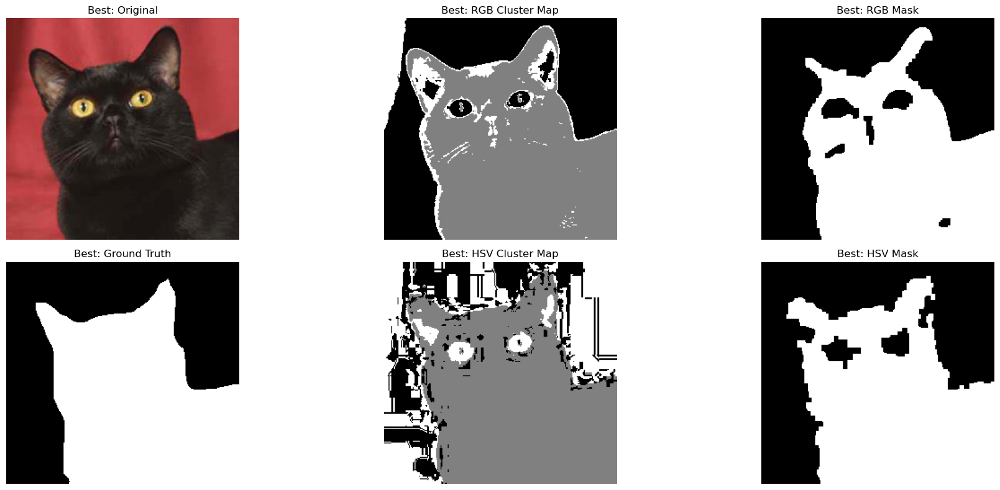

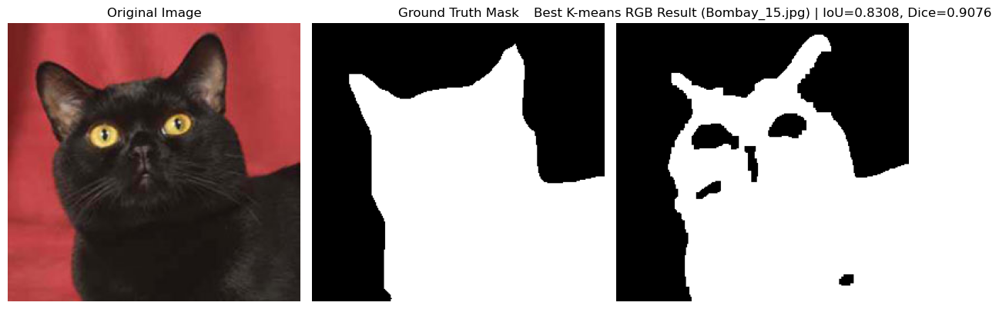

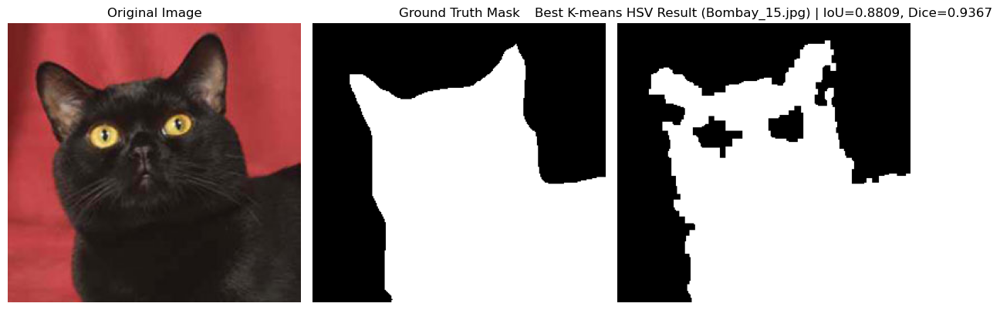

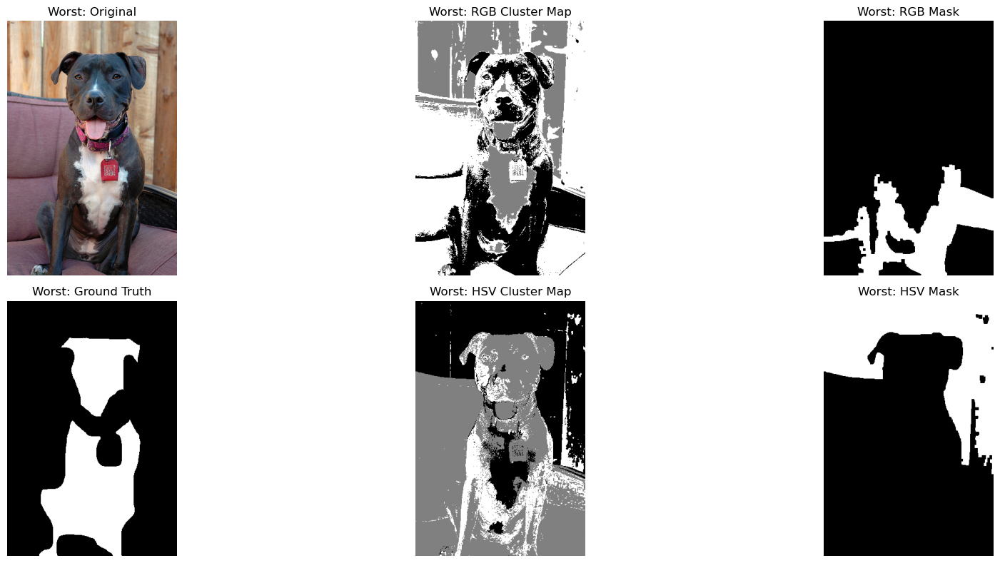

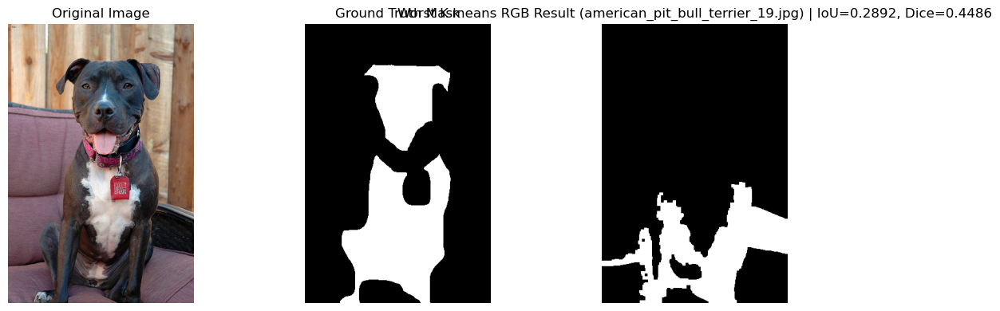

...

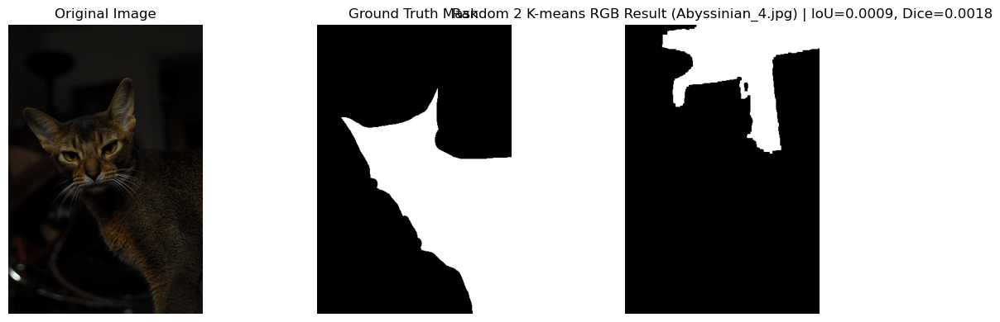

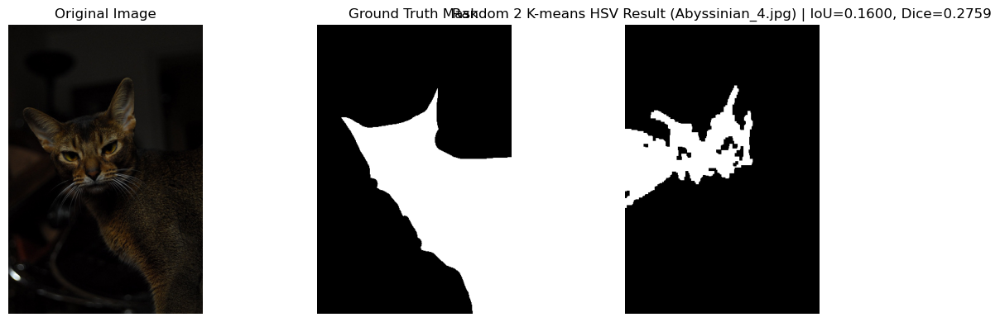

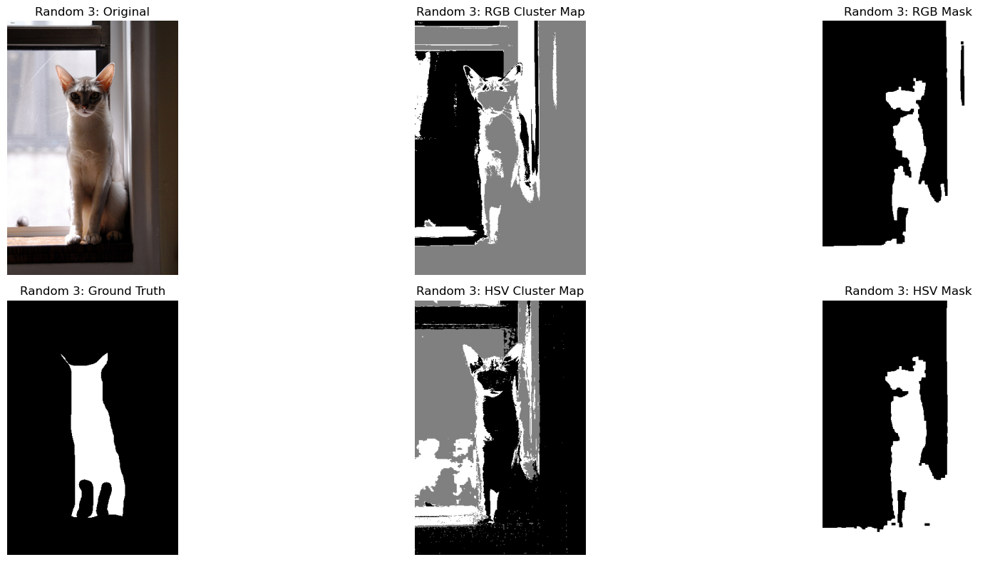

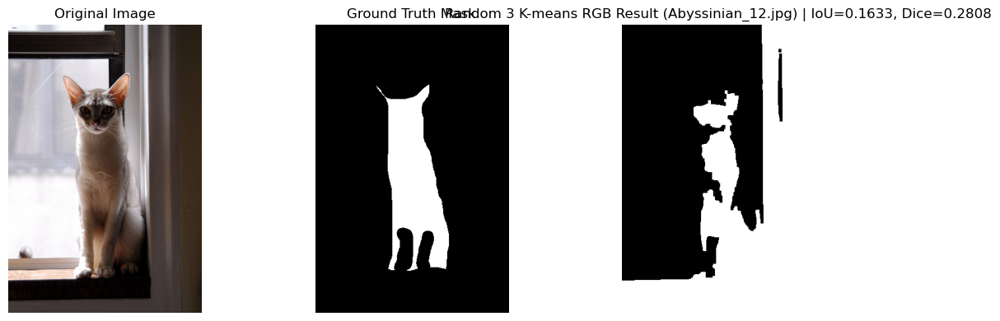

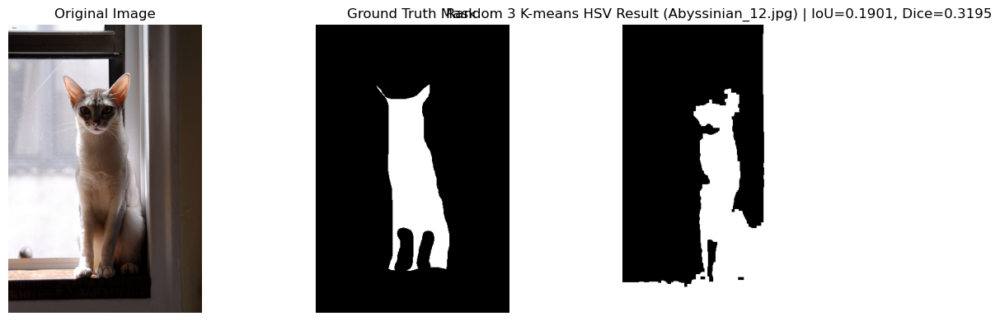

In [22]:
# Task 3: Clustering-Based Segmentation - Batch Evaluation + 5 Visual Examples

import os
import random
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

# Settings
save_dir_rgb = "results/predictions_kmeans_rgb"
save_dir_hsv = "results/predictions_kmeans_hsv"
os.makedirs(save_dir_rgb, exist_ok=True)
os.makedirs(save_dir_hsv, exist_ok=True)

print_each_image = True
random.seed(42)

kmeans_results = []

# For global metrics
rgb_tp = 0
rgb_fp = 0
rgb_fn = 0

hsv_tp = 0
hsv_fp = 0
hsv_fn = 0


# 1. Batch process full dataset
for idx, (img_path, mask_path) in enumerate(tqdm(zip(image_paths, mask_paths), total=len(image_paths))):
    image = load_image(img_path)
    gt_mask = load_mask(mask_path)

    # Ensure GT is binary
    gt_mask = (gt_mask > 0).astype(np.uint8)

    # RGB features
    pred_mask_rgb, label_map_rgb = kmeans_segmentation(image, feature_type="rgb", k=3)
    pred_mask_rgb = (pred_mask_rgb > 0).astype(np.uint8)

    iou_rgb = compute_iou(gt_mask, pred_mask_rgb)
    dice_rgb = compute_dice(gt_mask, pred_mask_rgb)

    # Global counts for RGB
    tp, fp, fn = compute_confusion_counts(gt_mask, pred_mask_rgb)
    rgb_tp += tp
    rgb_fp += fp
    rgb_fn += fn

    # HSV features
    pred_mask_hsv, label_map_hsv = kmeans_segmentation(image, feature_type="hsv", k=3)
    pred_mask_hsv = (pred_mask_hsv > 0).astype(np.uint8)

    iou_hsv = compute_iou(gt_mask, pred_mask_hsv)
    dice_hsv = compute_dice(gt_mask, pred_mask_hsv)

    # Global counts for HSV
    tp, fp, fn = compute_confusion_counts(gt_mask, pred_mask_hsv)
    hsv_tp += tp
    hsv_fp += fp
    hsv_fn += fn

    # Save predictions
    base_name = os.path.splitext(os.path.basename(img_path))[0]

    save_path_rgb = os.path.join(save_dir_rgb, f"{base_name}_kmeans_rgb.png")
    save_path_hsv = os.path.join(save_dir_hsv, f"{base_name}_kmeans_hsv.png")

    cv2.imwrite(save_path_rgb, (pred_mask_rgb * 255).astype(np.uint8))
    cv2.imwrite(save_path_hsv, (pred_mask_hsv * 255).astype(np.uint8))

    if print_each_image:
        print(
            f"{os.path.basename(img_path)} | "
            f"RGB: IoU={iou_rgb:.3f}, Dice={dice_rgb:.3f} | "
            f"HSV: IoU={iou_hsv:.3f}, Dice={dice_hsv:.3f}"
        )

    kmeans_results.append({
        "idx": idx,
        "img_path": img_path,
        "mask_path": mask_path,
        "image_name": os.path.basename(img_path),
        "image": image,
        "gt_mask": gt_mask,

        "pred_mask_rgb": pred_mask_rgb,
        "label_map_rgb": label_map_rgb,
        "iou_rgb": iou_rgb,
        "dice_rgb": dice_rgb,
        "save_path_rgb": save_path_rgb,

        "pred_mask_hsv": pred_mask_hsv,
        "label_map_hsv": label_map_hsv,
        "iou_hsv": iou_hsv,
        "dice_hsv": dice_hsv,
        "save_path_hsv": save_path_hsv
    })


# 2. Summary metrics
kmeans_rgb_ious = [r["iou_rgb"] for r in kmeans_results]
kmeans_rgb_dices = [r["dice_rgb"] for r in kmeans_results]

kmeans_hsv_ious = [r["iou_hsv"] for r in kmeans_results]
kmeans_hsv_dices = [r["dice_hsv"] for r in kmeans_results]

rgb_global_iou = compute_global_iou(rgb_tp, rgb_fp, rgb_fn)
rgb_global_dice = compute_global_dice(rgb_tp, rgb_fp, rgb_fn)

hsv_global_iou = compute_global_iou(hsv_tp, hsv_fp, hsv_fn)
hsv_global_dice = compute_global_dice(hsv_tp, hsv_fp, hsv_fn)

print("\n--- Task 3: K-means Clustering Batch Evaluation ---")
print(f"Total images processed: {len(kmeans_results)}")

print("\nRGB Features:")
print(f"Average IoU (K-means RGB): {np.mean(kmeans_rgb_ious):.4f}")
print(f"Average Dice (K-means RGB): {np.mean(kmeans_rgb_dices):.4f}")
print(f"Global IoU (K-means RGB): {rgb_global_iou:.4f}")
print(f"Global Dice (K-means RGB): {rgb_global_dice:.4f}")

print("\nHSV Features:")
print(f"Average IoU (K-means HSV): {np.mean(kmeans_hsv_ious):.4f}")
print(f"Average Dice (K-means HSV): {np.mean(kmeans_hsv_dices):.4f}")
print(f"Global IoU (K-means HSV): {hsv_global_iou:.4f}")
print(f"Global Dice (K-means HSV): {hsv_global_dice:.4f}")


# 3. Best and worst case
#    Use HSV for case selection if HSV performs better overall,
#    otherwise use RGB
use_hsv_for_selection = np.mean(kmeans_hsv_ious) >= np.mean(kmeans_rgb_ious)

if use_hsv_for_selection:
    best_case = max(kmeans_results, key=lambda x: x["iou_hsv"])
    worst_case = min(kmeans_results, key=lambda x: x["iou_hsv"])
    selection_mode = "HSV"
else:
    best_case = max(kmeans_results, key=lambda x: x["iou_rgb"])
    worst_case = min(kmeans_results, key=lambda x: x["iou_rgb"])
    selection_mode = "RGB"

print(f"\nCase selection based on better overall feature set: {selection_mode}")

print("\nBest Case:")
print(
    f"Index: {best_case['idx']}, Image: {best_case['image_name']}, "
    f"RGB IoU: {best_case['iou_rgb']:.4f}, RGB Dice: {best_case['dice_rgb']:.4f}, "
    f"HSV IoU: {best_case['iou_hsv']:.4f}, HSV Dice: {best_case['dice_hsv']:.4f}"
)

print("\nWorst Case:")
print(
    f"Index: {worst_case['idx']}, Image: {worst_case['image_name']}, "
    f"RGB IoU: {worst_case['iou_rgb']:.4f}, RGB Dice: {worst_case['dice_rgb']:.4f}, "
    f"HSV IoU: {worst_case['iou_hsv']:.4f}, HSV Dice: {worst_case['dice_hsv']:.4f}"
)


# 4. Select 3 random examples
remaining_cases = [
    r for r in kmeans_results
    if r["idx"] not in [best_case["idx"], worst_case["idx"]]
]
random_cases = random.sample(remaining_cases, 3)

print("\nRandom Examples:")
for i, case in enumerate(random_cases, 1):
    print(
        f"Random {i}: Index {case['idx']}, Image: {case['image_name']}, "
        f"RGB IoU: {case['iou_rgb']:.4f}, HSV IoU: {case['iou_hsv']:.4f}"
    )


# 5. Helper function to display
def show_kmeans_case_details(case, label="Example"):
    plt.figure(figsize=(20, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(case["image"])
    plt.title(f"{label}: Original")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(case["label_map_rgb"], cmap="gray")
    plt.title(f"{label}: RGB Cluster Map")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(case["pred_mask_rgb"], cmap="gray")
    plt.title(f"{label}: RGB Mask")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(case["gt_mask"], cmap="gray")
    plt.title(f"{label}: Ground Truth")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(case["label_map_hsv"], cmap="gray")
    plt.title(f"{label}: HSV Cluster Map")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(case["pred_mask_hsv"], cmap="gray")
    plt.title(f"{label}: HSV Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    show_results(
        case["image"],
        case["gt_mask"],
        case["pred_mask_rgb"],
        title=f"{label} K-means RGB Result ({case['image_name']}) | IoU={case['iou_rgb']:.4f}, Dice={case['dice_rgb']:.4f}"
    )

    show_results(
        case["image"],
        case["gt_mask"],
        case["pred_mask_hsv"],
        title=f"{label} K-means HSV Result ({case['image_name']}) | IoU={case['iou_hsv']:.4f}, Dice={case['dice_hsv']:.4f}"
    )


# 6. Show 5 qualitative examples
show_kmeans_case_details(best_case, label="Best")
show_kmeans_case_details(worst_case, label="Worst")

for i, case in enumerate(random_cases, 1):
    show_kmeans_case_details(case, label=f"Random {i}")

In [ ]:
# Task 4:  Comparison and my insights

Task 4: Comparison of Segmentation Methods
        Task             Method          Feature / Variant  Global IoU  Global Dice  IoU Rank  Dice Rank
      Task 1         Edge-Based Canny + contour refinement    0.291635     0.451575         1          1
Task 3 (HSV) K-means Clustering               HSV features    0.259554     0.412136         2          2
Task 3 (RGB) K-means Clustering               RGB features    0.221080     0.362105         3          3
      Task 2       Region-Based             Region Growing    0.135670     0.238926         4          4

Key Findings:
Best by IoU  : Task 1 - Edge-Based (Canny + contour refinement)
Worst by IoU : Task 2 - Region-Based (Region Growing)
Best by Dice : Task 1 - Edge-Based (Canny + contour refinement)
Worst by Dice: Task 2 - Region-Based (Region Growing)

Performance Analysis:
Task 2 vs Task 1 IoU difference: -0.1560
Task 3 HSV vs Task 3 RGB IoU difference: 0.0385
Task 3 HSV vs Task 1 IoU difference: -0.0321
Task 3 HSV vs Task 2 IoU

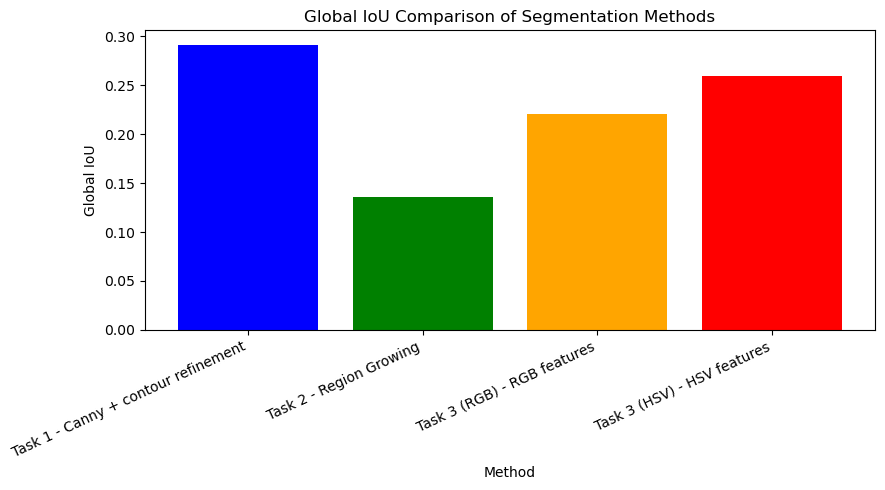

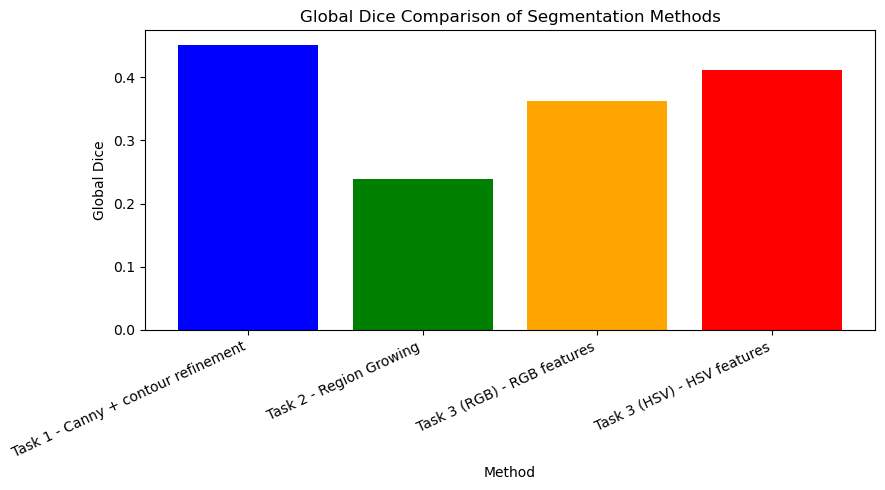

In [23]:
# Task 4: Comparison of All Segmentation Tasks using Global IoU / Dice

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

results = {
    "Task": [
        "Task 1",
        "Task 2",
        "Task 3 (RGB)",
        "Task 3 (HSV)"
    ],
    "Method": [
        "Edge-Based",
        "Region-Based",
        "K-means Clustering",
        "K-means Clustering"
    ],
    "Feature / Variant": [
        "Canny + contour refinement",
        "Region Growing",
        "RGB features",
        "HSV features"
    ],
    "Global IoU": [
        edge_global_iou,
        region_global_iou,
        rgb_global_iou,
        hsv_global_iou
    ],
    "Global Dice": [
        edge_global_dice,
        region_global_dice,
        rgb_global_dice,
        hsv_global_dice
    ]
}

df = pd.DataFrame(results)

df["IoU Rank"] = df["Global IoU"].rank(ascending=False, method="min").astype(int)
df["Dice Rank"] = df["Global Dice"].rank(ascending=False, method="min").astype(int)

df_sorted = df.sort_values(by="Global IoU", ascending=False).reset_index(drop=True)

print("Task 4: Comparison of Segmentation Methods")
print(df_sorted.to_string(index=False))

best_iou_method = df_sorted.iloc[0]
worst_iou_method = df_sorted.iloc[-1]

best_dice_method = df.sort_values(by="Global Dice", ascending=False).iloc[0]
worst_dice_method = df.sort_values(by="Global Dice", ascending=True).iloc[0]

print("\nKey Findings:")
print(f"Best by IoU  : {best_iou_method['Task']} - {best_iou_method['Method']} ({best_iou_method['Feature / Variant']})")
print(f"Worst by IoU : {worst_iou_method['Task']} - {worst_iou_method['Method']} ({worst_iou_method['Feature / Variant']})")
print(f"Best by Dice : {best_dice_method['Task']} - {best_dice_method['Method']} ({best_dice_method['Feature / Variant']})")
print(f"Worst by Dice: {worst_dice_method['Task']} - {worst_dice_method['Method']} ({worst_dice_method['Feature / Variant']})")

print("\nPerformance Analysis:")
print(f"Task 2 vs Task 1 IoU difference: {region_global_iou - edge_global_iou:.4f}")
print(f"Task 3 HSV vs Task 3 RGB IoU difference: {hsv_global_iou - rgb_global_iou:.4f}")
print(f"Task 3 HSV vs Task 1 IoU difference: {hsv_global_iou - edge_global_iou:.4f}")
print(f"Task 3 HSV vs Task 2 IoU difference: {hsv_global_iou - region_global_iou:.4f}")

print(f"Task 2 vs Task 1 Dice difference: {region_global_dice - edge_global_dice:.4f}")
print(f"Task 3 HSV vs Task 3 RGB Dice difference: {hsv_global_dice - rgb_global_dice:.4f}")
print(f"Task 3 HSV vs Task 1 Dice difference: {hsv_global_dice - edge_global_dice:.4f}")
print(f"Task 3 HSV vs Task 2 Dice difference: {hsv_global_dice - region_global_dice:.4f}")

labels = df["Task"] + " - " + df["Feature / Variant"]
colors = ["blue", "green", "orange", "red"]

plt.figure(figsize=(9, 5))
plt.bar(labels, df["Global IoU"], color=colors)
plt.title("Global IoU Comparison of Segmentation Methods")
plt.xlabel("Method")
plt.ylabel("Global IoU")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(labels, df["Global Dice"], color=colors)
plt.title("Global Dice Comparison of Segmentation Methods")
plt.xlabel("Method")
plt.ylabel("Global Dice")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()